In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

csv_path = next(Path("../data/raw").glob("*.csv"))
print("Fichier :", csv_path.name)

df = pd.read_csv(csv_path)
df = df.drop(columns=["Unnamed: 0"], errors="ignore")   # ancienne colonne d'index si présente

# À ajuster d'après les colonnes affichées ci-dessous
TITLE_COL, TEXT_COL, LABEL_COL = "title", "text", "label"

print(df.shape)
print(df.columns.tolist())
df.head()

Fichier : WELFake_Dataset.csv
(72134, 3)
['title', 'text', 'label']


,title,text,label
0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,NaN,Did they post their votes for Hillary already?,1
2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72134 entries, 0 to 72133
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   title   71576 non-null  object
 1   text    72095 non-null  object
 2   label   72134 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 1.7+ MB
title    558
text      39
label      0
dtype: int64
label
1    37106
0    35028
Name: count, dtype: int64
label
1    0.514
0    0.486
Name: proportion, dtype: float64


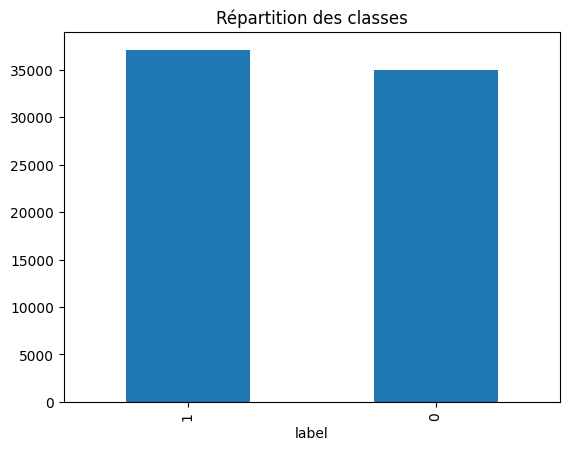

In [3]:
df.info()
print(df.isna().sum())

print(df[LABEL_COL].value_counts())
print(df[LABEL_COL].value_counts(normalize=True).round(3))
df[LABEL_COL].value_counts().plot(kind="bar", title="Répartition des classes")
plt.show()

In [5]:
print("Lignes entièrement dupliquées :", df.duplicated().sum())
print("Textes dupliqués :", df.duplicated(subset=[TEXT_COL]).sum())

conflit = df.dropna(subset=[TEXT_COL]).groupby(TEXT_COL)[LABEL_COL].nunique()
print("Textes avec des labels contradictoires :", (conflit > 1).sum())

Lignes entièrement dupliquées : 8456
Textes dupliqués : 9415
Textes avec des labels contradictoires : 1


         count   mean    std  min    25%    50%    75%      max
label                                                          
0      35028.0  577.6  563.1  0.0  241.0  427.0  783.0  14641.0
1      37067.0  506.1  677.3  0.0  217.0  369.0  568.0  24234.0
Textes de moins de 20 mots : 1808


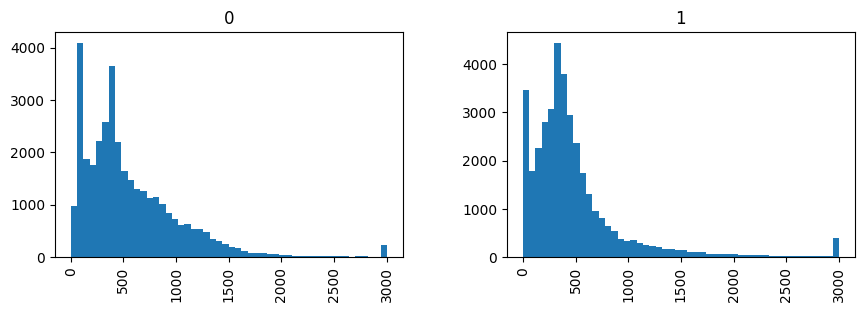

In [6]:
d = df.dropna(subset=[TEXT_COL]).copy()
d["n_words"] = d[TEXT_COL].str.split().str.len()

print(d.groupby(LABEL_COL)["n_words"].describe().round(1))
print("Textes de moins de 20 mots :", (d["n_words"] < 20).sum())

d["n_words"].clip(upper=3000).hist(by=d[LABEL_COL], bins=50, figsize=(10, 3))
plt.show()

In [7]:
for lab, g in df.dropna(subset=[TITLE_COL]).groupby(LABEL_COL):
    print(f"\n=== label {lab} ===")
    for t in g[TITLE_COL].sample(5, random_state=1):
        print("-", t[:100])


=== label 0 ===
- Candles May Have Caused Fire That Gutted Serbian Church, Officials Say - The New York Times
- Single Mother Seeks to Give Daughter the Peace That Eluded Her - The New York Times
- Cliff Sims: House Healthcare Bill ’Still a Work in Progress’
- Only a Rumbling Volcano Could Make North Korea and the West Play Nice - The New York Times
- New Ontario Law Enables Gov’t to Seize Children from Parents Opposing Gender Transition

=== label 1 ===
- “Sex Shop Kierkegaard: punto de encuentro para amantes del placer intelectual”
- FATHER OF STUDENT Released From N. Korean Prison Slams Obama…Uses ONE WORD To Describe President Tru
- The Path To Total Dictatorship: America’s “Shadow Government” And Its Silent Coup
- John Derbyshire On Peter Thiel On Trump
- TEXAS PIG FARMER Has BRILLIANT Idea After Muslims DEMAND He Moves So They Can Build A Mosque [VIDEO]


In [8]:
from sklearn.feature_extraction.text import CountVectorizer

for lab, g in d.groupby(LABEL_COL):
    cv = CountVectorizer(stop_words="english", max_features=15)
    X = cv.fit_transform(g[TEXT_COL].sample(min(5000, len(g)), random_state=1))
    top = sorted(zip(cv.get_feature_names_out(), X.sum(axis=0).A1), key=lambda x: -x[1])
    print(f"\nlabel {lab} :", top)


label 0 : [('said', np.int64(26560)), ('trump', np.int64(15266)), ('mr', np.int64(10353)), ('president', np.int64(7519)), ('people', np.int64(6117)), ('new', np.int64(6058)), ('state', np.int64(5490)), ('states', np.int64(4321)), ('government', np.int64(4256)), ('clinton', np.int64(4175)), ('reuters', np.int64(4146)), ('house', np.int64(4072)), ('year', np.int64(3996)), ('republican', np.int64(3805)), ('united', np.int64(3749))]

label 1 : [('trump', np.int64(14046)), ('said', np.int64(6687)), ('clinton', np.int64(6515)), ('people', np.int64(6430)), ('president', np.int64(5243)), ('hillary', np.int64(4536)), ('just', np.int64(4526)), ('like', np.int64(4181)), ('new', np.int64(3931)), ('obama', np.int64(3770)), ('time', np.int64(3528)), ('state', np.int64(3299)), ('donald', np.int64(3292)), ('news', np.int64(2912)), ('american', np.int64(2860))]


In [9]:
for pat in ["Reuters", "Twitter", "Getty Images", "Featured image", "Read more"]:
    has = d[TEXT_COL].str.contains(pat, case=False, regex=False)
    print(pat, has.groupby(d[LABEL_COL]).mean().round(3).to_dict())

Reuters {0: 0.618, 1: 0.018}
Twitter {0: 0.162, 1: 0.199}
Getty Images {0: 0.0, 1: 0.109}
Featured image {0: 0.0, 1: 0.227}
Read more {0: 0.004, 1: 0.081}
